In [4]:
#importing the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
#DOWNLOADING THE DATASET FROM KAGGLE
import kagglehub
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print(path)

C:\Users\Sakshi\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3


In [6]:
#SETTING UP THE PATH 
import pandas as pd, os
df = pd.read_csv(os.path.join(path, "creditcard.csv"))

#SAVING THE DATASET TO A LOCAL FILE
os.makedirs("../data/raw", exist_ok=True)
df.to_csv("../data/raw/creditcard.csv", index=False)

In [7]:
#LOADING THE DATASET AND INSPECTING IT
df = pd.read_csv("../data/raw/creditcard.csv")
print(df.shape)                      # (284807, 31)
df.info()
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True) * 100)
df.describe().T

(284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


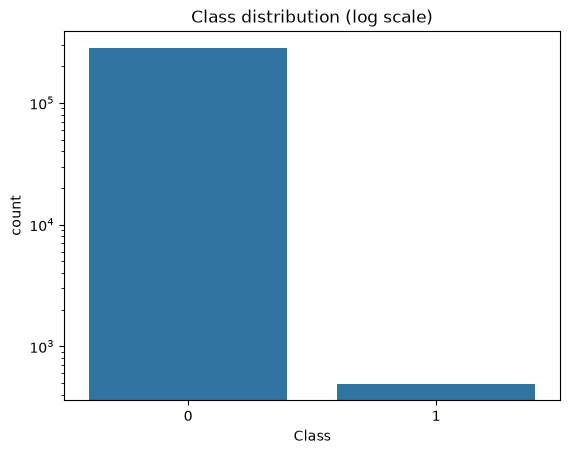

In [8]:
#EXPLORATORY DATA ANALYSIS (EDA)

#PLOT 1:Class imbalance
sns.countplot(x="Class", data=df)
plt.yscale("log"); plt.title("Class distribution (log scale)")  #IN THESE DATSETS THE IMBALANCE IS USUALLY EXTREME THAT'S WHY WE USE LOGARTHMIC SCALE TO VISUALIZE THE CLASS DISTRIBUTION
plt.show()

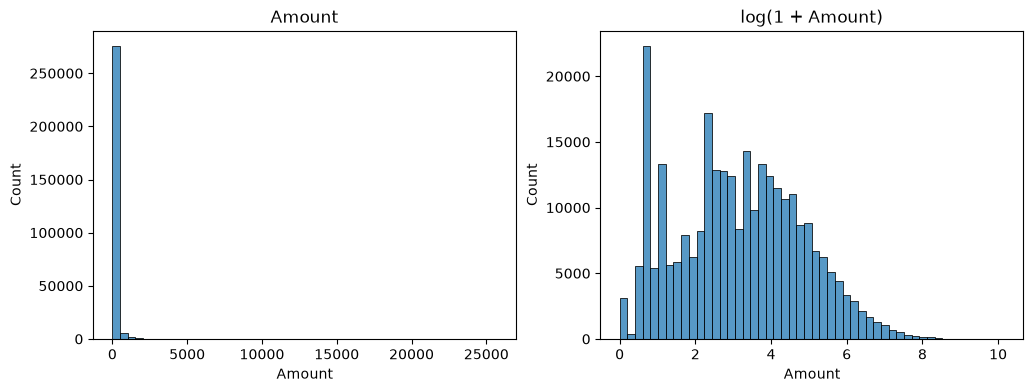

In [9]:
#PLOT 2: AMOUNT: RAW TRANSACTIONS ARE HEAVILY SKEWED, SO WE USE LOG-TRANSFORMATION FOR BETTER VISUALIZATION
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Amount"], bins=50, ax=ax[0]); ax[0].set_title("Amount") #PLOTS HISTOGRAM OF RAW TRANSACTION AMOUMNTS
sns.histplot(np.log1p(df["Amount"]), bins=50, ax=ax[1]); ax[1].set_title("log(1 + Amount)") #PLOTS HISTOGRAM OF LOG-CHANGED TRANSACTION AMOUNTS
plt.show()

In [ ]:
#PLOT 3: TO CHECK IF THE AMOUNT DIFFERENT FOR FRUADS BY COMPARING MEDIANS
#NORMAL: 0 ; FRAUD: 1
print(df.groupby("Class")["Amount"].describe())

#THE FRAUD AMOUNTS ARE WAY TOO SMALL RATHER THAN HUGE, SO WE CAN SAY THAT FRAUDS ARE NOT NECESSARILY BIGGER TRANSACTIONS, BUT THEY ARE USUALLY SMALLER THAN NORMAL TRANSACTIONS.

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


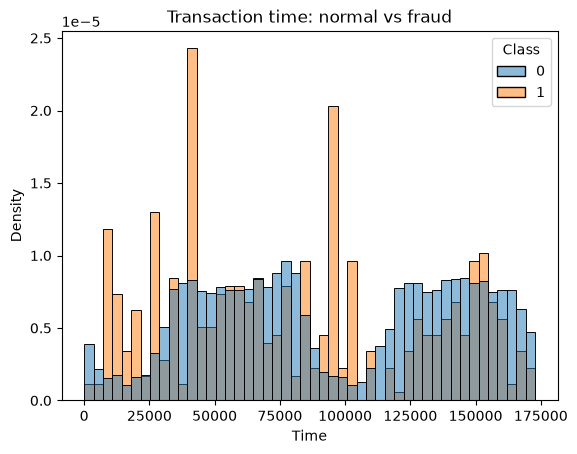

In [ ]:
#PLOT 4: TO CHECK AT WHAT TIMES FRAUDS OCCUR, WE CAN PLOT THE TIME DISTRIBUTION OF FRAUDS AND NON-FRAUDS
sns.histplot(data=df, x="Time", hue="Class", bins=48,
             stat="density", common_norm=False)
plt.title("Transaction time: normal vs fraud")
plt.show()
#WE DIVIDED THE TIME INTO 48 BINS, EACH BIN REPRESENTS 30 MINUTES.
#WE CAN SEE THAT FRAUDS ARE MORE LIKELY TO OCCUR DURING THE NIGHT, WHILE NORMAL TRANSACTIONS ARE MORE LIKELY TO OCCUR DURING THE DAY.

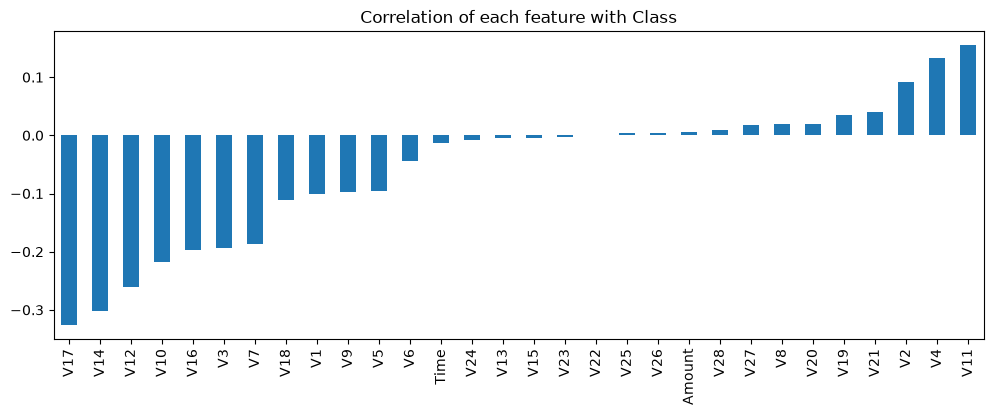

In [ ]:
#PLOT 5: TO FIND OUT WHICH FEATURES ARE MOST RELATED TO THE FRAUDS 
corr = df.corr()["Class"].drop("Class").sort_values()
corr.plot(kind="bar", figsize=(12, 4),
          title="Correlation of each feature with Class")
plt.show()
#THIS PLOT PROVES THAT THE FRUADS LEAVE SIGNALS IN OUR DATA WHICH CAN BE DETECTED BY OUR MODEL 
#ONLY 0.17% OF TRANSACTIONS ARE FRUADS, SO THE CLASS IS EXTREMELY IMBALANCED

In [13]:
#SAVING THE PLOTS FOR THE README FILE
import os
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/amount_distribution.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>